# R2: Where can SeasonBlend still gain leaderboard points, and does an ENSO/IOD prior help?

Competition research notebook, ECMWF AI Weather Quest (team NyarangaS2S, model SeasonBlend).
It runs top to bottom from `notebooks/` with the research venv (`.venv-research`). Every
number comes from real data cached by the pipeline: ECMWF IFS ENS runs of 2026
(dynamical.org), official ERA5 weekly files and quintile boundaries (ECBox), ERA5 daily 2 m
temperature 2004-2026 (Copernicus CDS), and the NOAA CPC Niño 3.4 and BoM Dipole Mode
Index weekly series.

**Operational safety.** Nothing here touches SeasonBlend. It reads `data/params.json` and
the research caches only and writes to `results/experiments/R2/`. The operational model,
its parameters and its submission files are unchanged, and nothing is submitted.

Sections:
1. Set-up and provenance
2. Official scoring and rules that decide what is worth doing
3. Where SeasonBlend loses points (R1 weaknesses, quantified)
4. ENSO/IOD-conditioned prior: ERA5 pilot (2 m temperature, 2005-2025, leave-one-ENSO-year-out)
5. Integration into SeasonBlend on the 2026 forecasts (weights fixed, then refitted)
6. Lagged ensemble pilot (earlier ECMWF runs of the same week)
7. Ranking of next experiments and decision

In [1]:
import sys, os, json, time, subprocess, platform, datetime as dt
from pathlib import Path
ROOT = Path(os.environ.get("AIWQ_ROOT", Path.cwd()))
while not (ROOT / "config.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt, scipy
from aiwq import r1, r2, calib
from aiwq.grid import LAT, LON, area_weights
from aiwq.config import load_config, VARIABLES, WINDOWS
from aiwq.obs import get_lsm
from aiwq.fit import score_weights
from aiwq.dates import day_of_year
from aiwq.indices import Indices

cfg = load_config(ROOT / "config.toml", experiment="control")
RD = cfg.data_dir / "research"
OUT = ROOT / "results" / "experiments" / "R2"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
PAIRS = [(v, w) for v in VARIABLES for w in WINDOWS]
NAMES = {"tas": "2 m temperature", "mslp": "Mean sea level pressure", "pr": "Precipitation"}
WIN = {1: "days 19-25", 2: "days 26-32"}
plt.rcParams.update({"font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9, "legend.fontsize": 8,
                     "figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False})

def savefig(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")

rows = {p: np.load(RD / f"rows_{p[0]}_p{p[1]}.npz") for p in PAIRS}
control = json.loads(cfg.params_path.read_text())
commit = subprocess.run(["git", "-C", str(ROOT), "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip()
branch = subprocess.run(["git", "-C", str(ROOT), "branch", "--show-current"], capture_output=True, text=True).stdout.strip()
t_start = time.time()
print("branch", branch, "| commit", commit, "| python", platform.python_version(), "| numpy", np.__version__)

branch research/r2 | commit 1299384 | python 3.14.2 | numpy 2.5.4


## 2. Official scoring and rules that decide what is worth doing

Read on the competition website on 19 November 2026
([submitting forecasts](https://aiweatherquest.ecmwf.int/submitting-forecasts/),
[evaluation system](https://aiweatherquest.ecmwf.int/evaluation/),
[terms](https://aiweatherquest.ecmwf.int/terms-of-ai-weather-quest/)):

| Item | What the pages say | Consequence |
|---|---|---|
| Deadline | Submission closes at the end of day 4 (worked example: Sunday 15 Nov 2026 23:59 UTC for the 12 Nov init) | 19 Nov init closes **Sunday 22 Nov 23:59 UTC** |
| Models | Up to 5 models per team (submitting page and T&C 4.2) | Room for a second model without touching SeasonBlend |
| Period ranking | A model must submit every week of the 13-week period with the same model; only minimal changes within a period | A new model cannot be period-ranked in DJF 2026; SeasonBlend stays frozen to 4 Feb 2027 |
| Inputs | Any data with a timestamp at or before Thursday 00 UTC; other forecast datasets allowed | Climate indices at init and **ECMWF runs from Monday-Wednesday of the same week are allowed**; Friday/Saturday runs are not |
| Score | RPSS against a 20 % climatology, per variable and window; tas and pr over land (≥ 50 %), pr without arid points, mslp everywhere; area weighted; headline = mean over tas, mslp, pr | Every variable is a third of the headline; the two windows count equally |
| Period aggregation | The page says it compares summed RPS "at every temporal and spatial point" and, elsewhere, "mean skill scores across all evaluated weeks" | Both conventions are reported below (ratio and mean of weekly RPSS) |
| Africa leaderboard | Not on the website yet (ArcX funding is mentioned only) | Global headline score decides; Africa is reported as a diagnostic |
| MJO, tropical storms | Own leaderboards (Brier skill score for MJO); not in the tas/mslp/pr mean | Separate track, not covered here |

The `status --remote` check on 18 Nov 22:22 UTC found the pipeline healthy (password set,
46 cached Thursday runs, ERA5 weeks to 2 Nov). The 19 Nov run is due on dynamical.org about
Saturday 21 Nov 00 UTC. The archive also holds a 00 UTC run for **every day** since 1 Jan 2026,
which Section 6 uses.

## 3. Where SeasonBlend loses points

All numbers are cross-validated (leave one week out, ±21 days excluded) on the 42 verified 2026
initialisations, as in R1. Each weakness is converted into **points of the headline score**,
the mean RPSS over the six variable/window pairs, so they can be compared directly.

* **Weight noise:** in-sample minus cross-validated RPSS. This is the most that better-estimated
  settings and weights could add with the same method, for example from more training weeks.
* **Calibration headroom:** the reliability term of the RPS (cumulative-threshold Brier
  decomposition, 20 bins) divided by the climatological RPS. It is the most a perfect
  recalibration of SeasonBlend's own probabilities could add, measured in-sample, so it is an
  upper bound. The coldest-quintile share is the first threshold.
* **Southern band:** cross-validated SeasonBlend minus the raw ensemble south of 30°S.

In [2]:
bands = r1.Scheme("SeasonBlend (3 bands)", r1.band_basis())
def ctrl_combo(z):
    L, S, P = z["terms"].shape[:3]
    return int(np.ravel_multi_index(tuple(z["control_combo"]), (L, S, P)))

def row_rps(T, a, c):
    S11, S12, S22, R1_, R2_, YY = (T[:, k] for k in range(6))
    return a * a * S11 + 2 * a * c * S12 + c * c * S22 - 2 * a * R1_ - 2 * c * R2_ + YY

cv, cvfix, probs = {}, {}, {}
weak = []
south = LAT < -30
for v, w in PAIRS:
    z = rows[(v, w)]; k = ctrl_combo(z); excl = int(z["exclude_days"])
    L_, S_, P_ = z["terms"].shape[:3]
    flat = z["terms"].reshape(L_ * S_ * P_, *z["terms"].shape[3:])
    res = r1.cv_scores(z["terms"], z["mon_ord"], excl, bands); cv[(v, w)] = res
    fix = r1.cv_scores(z["terms"], z["mon_ord"], excl, bands, combos=[k]); cvfix[(v, w)] = fix
    ins = r1.in_sample(z["terms"], bands, k)[4]
    # gridded cross-validated SeasonBlend probabilities (SeasonBlend's settings, fold weights)
    pe, pp, oh = z["p_ens"].astype(float), z["p_prior"].astype(float), z["onehot"].astype(float)
    P = np.stack([calib.finalize(fix.a_rows[i][None, :, None] * pe[i] + fix.c_rows[i][None, :, None] * pp[i]
                                 + (1 - fix.a_rows[i] - fix.c_rows[i])[None, :, None] * 0.2) for i in range(len(pe))])
    probs[(v, w)] = P
    Wv = np.where(np.isfinite(oh[:, 0]), z["score_weight"][None], 0.0)
    rel = r2.rps_reliability(P, np.nan_to_num(oh), Wv)
    climsum = fix.clim.sum()
    # southern band: CV SeasonBlend vs raw ensemble (lambda 0, spread 1, no smoothing, a = 1)
    kr = np.ravel_multi_index((list(z["lambdas"]).index(0.0), list(z["spreads"]).index(1.0), list(z["sigmas"]).index(0.0)), (L_, S_, P_))
    sb_s = sum(row_rps(flat[k, i], fix.a_rows[i], fix.c_rows[i])[south].sum() for i in range(len(pe)))
    raw_s = sum(row_rps(flat[kr, i], np.ones(121), np.zeros(121))[south].sum() for i in range(len(pe)))
    weak.append({"variable": v, "window": w, "N": len(res.rps),
                 "CV RPSS (lb)": res.rpss_leaderboard, "CV RPSS (ratio)": res.rpss_ratio,
                 "in-sample RPSS": ins, "weight noise (ratio pts)": ins - fix.rpss_ratio,
                 "calibration headroom": rel.sum() / climsum, "coldest-quintile headroom": rel[0] / climsum,
                 "warmest-quintile headroom": rel[3] / climsum,
                 "south of 30S: SB minus raw": (raw_s - sb_s) / climsum})
weak = pd.DataFrame(weak)
mean_row = weak.drop(columns=["variable", "window", "N"]).mean()
weak.loc[len(weak)] = {"variable": "mean (= headline points)", "window": "", "N": "", **mean_row.to_dict()}
weak.to_csv(OUT / "R2_weakness_points.csv", index=False)
print("Weaknesses in RPSS points; the last row is the effect on the headline score (mean of the six pairs)")
weak.round(4)

Weaknesses in RPSS points; the last row is the effect on the headline score (mean of the six pairs)


C:\Users\Stephen Nyaranga\AppData\Local\Temp\ipykernel_30840\2321557221.py:40: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  weak.loc[len(weak)] = {"variable": "mean (= headline points)", "window": "", "N": "", **mean_row.to_dict()}
C:\Users\Stephen Nyaranga\AppData\Local\Temp\ipykernel_30840\2321557221.py:40: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  weak.loc[len(weak)] = {"variable": "mean (= headline points)", "window": "", "N": "", **mean_row.to_dict()}


,variable,window,N,CV RPSS (lb),CV RPSS (ratio),in-sample RPSS,weight noise (ratio pts),calibration headroom,coldest-quintile headroom,warmest-quintile headroom,south of 30S: SB minus raw
0,tas,1,42,0.1079,0.1107,0.1148,0.0041,0.0045,0.0017,0.0010,0.0072
1,tas,2,41,0.0881,0.0907,0.0959,0.0052,0.0053,0.0018,0.0011,0.0069
2,mslp,1,42,0.1809,0.1864,0.1962,0.0035,0.0011,0.0003,0.0003,-0.0015
3,mslp,2,41,0.1403,0.1448,0.1544,0.0093,0.0035,0.0009,0.0009,-0.0009
4,pr,1,42,0.0815,0.0818,0.0834,0.0016,0.0023,0.0003,0.0004,-0.0012
5,pr,2,41,0.0707,0.0708,0.0725,0.0017,0.0028,0.0003,0.0005,-0.0011
6,mean (= headline points),,,0.1116,0.1142,0.1195,0.0042,0.0032,0.0009,0.0007,0.0016


### 3b. Regional and window breakdown, and the training-size learning curve

East Africa is scored on a handful of grid points, so its weight in the global headline is
small. The table converts each region's shortfall into headline points: the gain if that
region reached the skill SeasonBlend has over all of Africa.

The learning curve refits SeasonBlend's settings and weights with fewer training weeks (random
subsets, 8 repeats) and extrapolates, assuming RPSS(n) = RPSS(∞) − b/n, what more training
weeks would be worth. This is the case for reforecasts.

In [3]:
lon180 = np.where(LON > 180, LON - 360, LON)
LA, LO = np.meshgrid(LAT, lon180, indexing="ij")
REG = {"Tropics 30S-30N": np.abs(LA) <= 30, "N extratropics": LA > 30, "S extratropics": LA < -30,
       "Africa": (LA >= -35) & (LA <= 37.5) & (LO >= -18) & (LO <= 52),
       "Equatorial East Africa": (LA >= -5) & (LA <= 5) & (LO >= 33) & (LO <= 42),
       "Southern Africa": (LA >= -35) & (LA <= -15) & (LO >= 12) & (LO <= 40)}

def rps_field(p, oh):
    d = np.cumsum(p, 1)[:, :4] - np.cumsum(np.nan_to_num(oh), 1)[:, :4]
    r = (d * d).sum(1); r[~np.isfinite(oh[:, 0])] = np.nan
    return r

regtab = []
for v, w in PAIRS:
    z = rows[(v, w)]; oh = z["onehot"].astype(float); W = z["score_weight"]
    F = rps_field(probs[(v, w)], oh); Fc = rps_field(np.full_like(oh, 0.2), oh)
    tot_c = np.nansum(Fc * W)
    afr = 1 - np.nansum(F * W * REG["Africa"]) / np.nansum(Fc * W * REG["Africa"])
    for rn, m in REG.items():
        num, den = np.nansum(F * W * m), np.nansum(Fc * W * m)
        regtab.append({"region": rn, "variable": v, "window": w, "RPSS": 1 - num / den,
                       "share of global clim RPS": den / tot_c,
                       "headline pts if region reached Africa skill": max(0.0, (num - (1 - afr) * den) / tot_c) / 6})
regtab = pd.DataFrame(regtab)
regtab.to_csv(OUT / "R2_region_points.csv", index=False)
regsum = regtab.groupby("region", sort=False).agg({"RPSS": "mean", "share of global clim RPS": "mean",
                                                    "headline pts if region reached Africa skill": "sum"})
win = weak.iloc[:6].groupby("window")["CV RPSS (lb)"].mean()
print(f"Mean CV RPSS (lb): days 19-25 {win[1]:+.4f}, days 26-32 {win[2]:+.4f}")
regsum.round(4)

Mean CV RPSS (lb): days 19-25 +0.1234, days 26-32 +0.0997


,RPSS,share of global clim RPS,headline pts if region reached Africa skill
region,,,
Tropics 30S-30N,0.1879,0.4777,0.0030
N extratropics,0.0449,0.3583,0.0395
S extratropics,0.0465,0.1640,0.0166
Africa,0.1523,0.1839,0.0000
Equatorial East Africa,0.1321,0.0064,0.0004
Southern Africa,0.0782,0.0230,0.0017


Mean ratio RPSS over the six pairs by number of training weeks:
n_train
10    0.1122
15    0.1130
20    0.1137
25    0.1135
30    0.1137
36    0.1142
Fit RPSS(n) = 0.1147 - 0.026/n -> 36 weeks: +0.1140, 72 weeks: +0.1144, 144 weeks: +0.1146, 1000 weeks: +0.1147


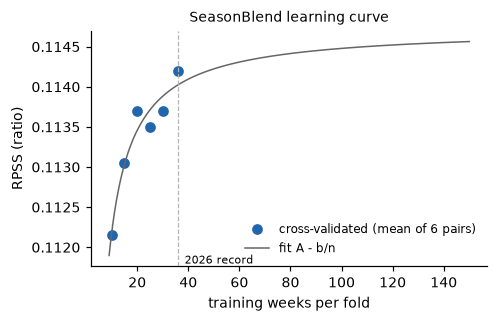

In [4]:
rng = np.random.default_rng(0)
NS = (10, 15, 20, 25, 30)
lc = []
for v, w in PAIRS:
    z = rows[(v, w)]; excl = int(z["exclude_days"])
    full = cv[(v, w)]
    for n in NS:
        vals = []
        for rep in range(8):
            rp, cl = r2.cv_subsample(z["terms"], z["mon_ord"], excl, bands, n, rng)
            ok = np.isfinite(rp)
            vals.append(1 - rp[ok].sum() / cl[ok].sum())
        lc.append({"variable": v, "window": w, "n_train": n, "RPSS": np.mean(vals), "sd": np.std(vals)})
    n_full = int(round(np.mean([(np.abs(z["mon_ord"] - m) >= excl).sum() for m in z["mon_ord"]])))
    lc.append({"variable": v, "window": w, "n_train": n_full, "RPSS": full.rpss_ratio, "sd": 0.0, "all weeks": True})
lc = pd.DataFrame(lc)
lc["all weeks"] = lc["all weeks"].fillna(False).astype(bool)
lc.loc[lc["all weeks"], "n_train"] = int(round(lc.loc[lc["all weeks"], "n_train"].mean()))  # 36-37 eligible weeks per fold
lcm = lc.groupby("n_train")["RPSS"].mean()
# RPSS(n) = A - b / n, least squares over the mean curve
Xl = np.c_[np.ones(len(lcm)), -1.0 / lcm.index.to_numpy()]
lc_A, lc_b = np.linalg.lstsq(Xl, lcm.to_numpy(), rcond=None)[0]
extrap = {f"{n} weeks": lc_A - lc_b / n for n in (int(lcm.index.max()), 2 * int(lcm.index.max()), 4 * int(lcm.index.max()), 1000)}
lc.to_csv(OUT / "R2_learning_curve.csv", index=False)
print("Mean ratio RPSS over the six pairs by number of training weeks:"); print(lcm.round(4).to_string())
print(f"Fit RPSS(n) = {lc_A:.4f} - {lc_b:.3f}/n -> " + ", ".join(f"{k}: {x:+.4f}" for k, x in extrap.items()))
fig, ax = plt.subplots(figsize=(4.6, 3))
ax.plot(lcm.index, lcm.values, "o", color="#2166ac", label="cross-validated (mean of 6 pairs)")
nn = np.linspace(9, 150, 200); ax.plot(nn, lc_A - lc_b / nn, "-", color="0.4", lw=1, label="fit A - b/n")
nf = lcm.index.max(); ax.axvline(nf, color="0.7", lw=0.8, ls="--"); ax.text(nf + 1, ax.get_ylim()[0], " 2026 record", va="bottom", fontsize=7)
ax.set_xlabel("training weeks per fold"); ax.set_ylabel("RPSS (ratio)"); ax.legend(frameon=False, loc="lower right")
ax.set_title("SeasonBlend learning curve"); fig.tight_layout(); savefig(fig, "fig1_learning_curve")

## 4. ENSO/IOD-conditioned prior: ERA5 pilot

**Data audit.** ERA5 daily fields come from the Copernicus CDS (`data/cds/<var>_daily_<year>.nc`,
1.5° daily means, about 30 minutes of CDS time per variable-year). 2 m temperature has been
cached for 2004-2026 since the R0 work. Precipitation 2004-2026 was downloaded for R2 once the
temperature pilot proved positive. Mean sea level pressure is cached only for 2004-2010 and is not
used: SeasonBlend gives its prior almost no weight for pressure (c ≈ 0-0.13), so a better
pressure prior cannot move the score. The pilot uses the scored land points: land ≥ 50 %, and for
precipitation without the arid points the leaderboard skips. It covers 21 ENSO years (July-June)
of Thursday initialisations, 2005-2025, for both windows. The indices are the ones the pipeline
already uses, taken as known at each initialisation: CPC weekly Niño 3.4 from 1990 and the BoM
weekly DMI, which starts in August 2008.

**Validation.** Leave one ENSO year out: every slope, trend and spread used for a held-out year
is fitted on the other years. The quintile boundaries for a week come from all other years, so
the target year never defines its own categories. Temperature anomalies are standardised.
Precipitation uses normal scores (ranks within the climatological sample), because weekly totals
are skewed. The uncertainty bootstrap resamples whole ENSO years, which are the independent units.

**Candidates.**
- `recent` is SeasonBlend's existing unconditioned prior: seasonally weighted quintile frequencies
  of the past 3 years, ending 6 days before initialisation.
- `ENSO` is a Gaussian-shift prior from the Niño 3.4 regression.
- `recent × ENSO` tilts the existing prior by the ENSO signal, p ∝ recent · g/0.2.
- The same is done for the IOD and for both indices together, with a shrinkage factor κ on the
  slopes.

In [5]:
from aiwq.cds import daily_path
KAPPAS = (0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5)
PILOT_VARS = [v for v in ("tas", "pr") if all(daily_path(cfg, v, y).exists() for y in range(2004, 2027))]
print("variables with a complete 2004-2026 ERA5 daily record:", PILOT_VARS)
lon180 = np.where(LON > 180, LON - 360, LON)
LA, LO = np.meshgrid(LAT, lon180, indexing="ij")
season_of = np.array(["DJF", "DJF", "MAM", "MAM", "MAM", "JJA", "JJA", "JJA", "SON", "SON", "SON", "DJF"])

lsm = get_lsm(cfg)

def run_pilot(var):
    t0 = time.time()
    Wv = score_weights(var, lsm)
    mask = Wv > 0
    daily = r2.load_daily(cfg, var, range(2004, 2027), mask)
    starts, wk = r2.weekly_means(daily)
    clim = r2.WeeklyClimate(starts, wk, range(2004, 2026))
    cases = r2.build_cases(cfg, starts, wk, clim, "2005-01-01", "2025-12-31",
                           zmode="rank" if var == "pr" else "std", arid_mask=(var == "pr"))
    pw = r2.point_weights(daily.points, Wv)
    Wc = np.ascontiguousarray(cases.weights(pw), dtype=np.float32)
    cs = lambda R: np.einsum("np,np->n", R, Wc)  # noqa: E731
    has_dmi = np.isfinite(cases.dmi)
    rec = r2.recent_prior(cases, starts, wk, clim, daily.points)
    del wk, starts, clim
    fits = {"ENSO": r2.fit_state(cases, ["nino34"], daily.points),
            "ENSO (DMI period)": r2.fit_state(cases, ["nino34"], daily.points, use=has_dmi),
            "IOD": r2.fit_state(cases, ["dmi"], daily.points, use=has_dmi),
            "ENSO+IOD": r2.fit_state(cases, ["nino34", "dmi"], daily.points, use=has_dmi)}
    Rclim = r2.rps(np.full((1, 5, 1), 0.2, np.float32), cases.oh); clim_case = cs(Rclim)
    Rrec = r2.rps(rec, cases.oh); rec_case = cs(Rrec)
    case_rps = {}
    for name, f in fits.items():
        for kap in KAPPAS:
            g = r2.gauss_probs(kap * np.nan_to_num(f.mu), np.nan_to_num(f.s, nan=1.0))
            case_rps[(name, "alone", kap)] = cs(r2.rps(g, cases.oh))
            case_rps[(name, "recent x", kap)] = cs(r2.rps(r2.tilt(rec, g), cases.oh))
            del g
    allc = np.ones(len(clim_case), bool)
    rpss = lambda r, sel: 1 - r[sel].sum() / clim_case[sel].sum()  # noqa: E731
    tab = []
    for name in fits:
        sel = allc if name == "ENSO" else has_dmi
        for kap in KAPPAS:
            tab.append({"variable": var, "predictors": name, "kappa": kap, "cases": int(sel.sum()),
                        "recent (existing prior)": rpss(rec_case, sel),
                        "state prior alone": rpss(case_rps[(name, "alone", kap)], sel),
                        "recent x state": rpss(case_rps[(name, "recent x", kap)], sel)})
    # nested choice of kappa: for each held-out year, the kappa that is best on the other years
    honest, chosen = [], {}
    for name in fits:
        sel = allc if name == "ENSO" else has_dmi
        folds = np.unique(cases.fold[sel])
        for kind in ("alone", "recent x"):
            S = {k: np.array([case_rps[(name, kind, k)][sel & (cases.fold == f)].sum() for f in folds]) for k in KAPPAS}
            r_ = np.full(len(clim_case), np.nan); ch = {}
            for j, f in enumerate(folds):
                best = min(KAPPAS, key=lambda k: S[k].sum() - S[k][j]); ch[f] = best
                m = sel & (cases.fold == f); r_[m] = case_rps[(name, kind, best)][m]
            chosen[(name, kind)] = ch
            base = rec_case if kind == "recent x" else clim_case
            bs = r2.year_bootstrap(base[sel], r_[sel], clim_case[sel], cases.fold[sel])
            honest.append({"variable": var, "candidate": (f"recent x {name}" if kind == "recent x" else f"{name} alone"),
                           "compared with": "recent" if kind == "recent x" else "climatology",
                           "cases": int(sel.sum()), "RPSS": rpss(r_, sel), "RPSS (lb)": float(np.mean(1 - r_[sel] / clim_case[sel])),
                           "baseline RPSS": rpss(base, sel), "delta": bs["delta"], "lo90": bs["lo90"], "hi90": bs["hi90"],
                           "P(no gain)": bs["p_le_0"], "years better": f'{bs["groups_better"]}/{bs["n_groups"]}',
                           "kappa chosen (median)": float(np.median(list(ch.values())))})
    # breakdowns for recent x ENSO at the nested kappa
    kap_star = float(np.median(list(chosen[("ENSO", "recent x")].values())))
    f = fits["ENSO"]
    g_best = r2.gauss_probs(kap_star * f.mu, f.s)
    P_best = r2.tilt(rec, g_best)
    Rbest = r2.rps(P_best, cases.oh)
    regm = {"Global land": np.ones(len(daily.points), bool), **{k: m.ravel()[daily.points] for k, m in REG.items()}}
    season = season_of[cases.start.month - 1]
    strength = np.where(np.abs(cases.nino34) >= 1.0, "|N34| >= 1", np.where(np.abs(cases.nino34) >= 0.5, "0.5-1", "< 0.5"))
    brk = []
    def add(group, label, sel, wmask=None):
        W_ = Wc[sel] if wmask is None else Wc[sel] * wmask[None]
        c = np.einsum("np,np->n", Rclim[sel], W_); a = np.einsum("np,np->n", Rrec[sel], W_); b = np.einsum("np,np->n", Rbest[sel], W_)
        bs = r2.year_bootstrap(a, b, c, cases.fold[sel], n_boot=2000)
        brk.append({"variable": var, "group": group, "subset": label, "cases": int(sel.sum()), "recent": 1 - a.sum() / c.sum(),
                    "recent x ENSO": 1 - b.sum() / c.sum(), "delta": bs["delta"], "lo90": bs["lo90"], "hi90": bs["hi90"]})
    for wv in (1, 2): add("window", WIN[wv], cases.window == wv)
    for s_ in ("DJF", "MAM", "JJA", "SON"): add("season of target", s_, season == s_)
    for s_ in ("|N34| >= 1", "0.5-1", "< 0.5"): add("ENSO strength at init", s_, strength == s_)
    for rn, m in regm.items(): add("region", rn, allc, m.astype(np.float32))
    rel = []
    for name, P_ in (("recent", rec), ("recent x ENSO", P_best), ("ENSO alone", g_best)):
        rc = r2.reliability_component(P_, cases.oh, Wc)
        rel.append({"variable": var, "prior": name, **{f"q{k + 1}": rc[k] * 1000 for k in range(5)}, "mean": rc.mean() * 1000})
    # per-year gain, slope map (mid-January target) and gain map
    yrs = np.unique(cases.fold)
    gain_case = rec_case - cs(Rbest)
    dy = np.array([gain_case[cases.fold == y].sum() / clim_case[cases.fold == y].sum() for y in yrs])
    n34y = np.array([np.nanmean(cases.nino34[cases.fold == y]) for y in yrs])
    _, _, B_m = r2.fit_predict(cases, ["nino34"], daily.points, allc, [15], np.array([[1.0]]))
    V = cases.valid if cases.valid is not None else 1.0
    gain_pt = ((Rrec - Rbest) * V).sum(0) / np.maximum((Rclim * V).sum(0), 1e-9)
    out = {"var": var, "cases": cases, "points": daily.points, "pw": pw, "chosen": chosen, "kap_star": kap_star,
           "tab": pd.DataFrame(tab), "honest": pd.DataFrame(honest), "brk": pd.DataFrame(brk), "rel": pd.DataFrame(rel),
           "yrs": yrs, "dy": dy, "n34y": n34y, "slope": B_m[0, 0], "gain_pt": gain_pt,
           "audit": (len(daily.points), str(daily.days[0].date()), str(daily.days[-1].date()), len(cases.init), int(has_dmi.sum())),
           "seconds": time.time() - t0}
    del rec, fits, g_best, P_best, Rbest, Rrec, Rclim, daily
    return out

PILOT = {}
for v in PILOT_VARS:
    PILOT[v] = run_pilot(v)
    a = PILOT[v]["audit"]
    print(f"{v}: {a[0]} scored land points, daily {a[1]} to {a[2]}, {a[3]} cases ({a[4]} with DMI), {PILOT[v]['seconds']:.0f} s")
c0 = PILOT[PILOT_VARS[0]]["cases"]
yr = pd.DataFrame({"fold": c0.fold, "nino34": c0.nino34, "dmi": c0.dmi})
audit = yr.groupby("fold").agg(nino34_mean=("nino34", "mean"), nino34_max=("nino34", "max"), nino34_min=("nino34", "min"),
                               dmi_mean=("dmi", "mean"), cases=("nino34", "size"))
audit["ENSO"] = np.where(audit["nino34_max"] >= 1.0, "El Nino", np.where(audit["nino34_min"] <= -1.0, "La Nina", "weak/neutral"))
audit.to_csv(OUT / "R2_pilot_folds.csv")
print("folds by ENSO class:", audit["ENSO"].value_counts().to_dict())

variables with a complete 2004-2026 ERA5 daily record: ['tas']


tas: 9839 scored land points, daily 2004-01-01 to 2026-11-09, 2190 cases (1816 with DMI), 803 s
folds by ENSO class: {'La Nina': 10, 'El Nino': 8, 'weak/neutral': 4}


In [6]:
tab = pd.concat([PILOT[v]["tab"] for v in PILOT_VARS], ignore_index=True)
tab.to_csv(OUT / "R2_pilot_kappa.csv", index=False)
print("Leave-one-ENSO-year-out RPSS against climatology (ratio convention), scored land points")
tab.round(4)

Leave-one-ENSO-year-out RPSS against climatology (ratio convention), scored land points


,variable,predictors,kappa,cases,recent (existing prior),state prior alone,recent x state
0,tas,ENSO,0.00,2190,-0.0124,-0.0010,-0.0118
1,tas,ENSO,0.25,2190,-0.0124,0.0058,-0.0050
2,tas,ENSO,0.50,2190,-0.0124,0.0103,-0.0003
3,tas,ENSO,0.75,2190,-0.0124,0.0125,0.0024
4,tas,ENSO,1.00,2190,-0.0124,0.0125,0.0031
5,tas,ENSO,1.25,2190,-0.0124,0.0105,0.0018
6,tas,ENSO,1.50,2190,-0.0124,0.0068,-0.0011
7,tas,ENSO (DMI period),0.00,1816,-0.0147,-0.0008,-0.0137
8,tas,ENSO (DMI period),0.25,1816,-0.0147,0.0058,-0.0068
9,tas,ENSO (DMI period),0.50,1816,-0.0147,0.0099,-0.0021


**Choosing κ without peeking.** For each held-out year, κ is chosen to maximise the score on
the *other* years; the held-out year is then scored with that κ. This nested score is the
honest estimate for each candidate. It is compared with the existing prior on identical cases,
with whole ENSO years resampled (90 % interval).

In [7]:
honest_tab = pd.concat([PILOT[v]["honest"] for v in PILOT_VARS], ignore_index=True)
honest_tab.to_csv(OUT / "R2_pilot_nested.csv", index=False)
honest_tab.round(4)

,variable,candidate,compared with,cases,RPSS,RPSS (lb),baseline RPSS,delta,lo90,hi90,P(no gain),years better,kappa chosen (median)
0,tas,ENSO alone,climatology,2190,0.0107,0.0103,0.0000,0.0107,0.0028,0.0193,0.0092,12/22,1.00
1,tas,recent x ENSO,recent,2190,0.0022,0.0016,-0.0124,0.0146,0.0066,0.0239,0.0000,18/22,1.00
2,tas,ENSO (DMI period) alone,climatology,1816,0.0116,0.0111,0.0000,0.0116,0.0035,0.0212,0.0020,12/18,0.75
3,tas,recent x ENSO (DMI period),recent,1816,-0.0002,-0.0009,-0.0147,0.0145,0.0048,0.0255,0.0015,14/18,1.00
4,tas,IOD alone,climatology,1816,0.0003,0.0003,0.0000,0.0003,-0.0010,0.0016,0.3578,11/18,0.50
5,tas,recent x IOD,recent,1816,-0.0124,-0.0126,-0.0147,0.0023,0.0004,0.0043,0.0222,13/18,0.50
6,tas,ENSO+IOD alone,climatology,1816,0.0095,0.0091,0.0000,0.0095,0.0025,0.0176,0.0065,10/18,0.75
7,tas,recent x ENSO+IOD,recent,1816,-0.0005,-0.0011,-0.0147,0.0143,0.0058,0.0243,0.0000,13/18,0.75


### 4b. Where and when the ENSO signal pays

The breakdowns use the nested `recent × ENSO` candidate on all years, against the existing prior
on the same cases. Regions are scored on their land points only.

In [8]:
brk = pd.concat([PILOT[v]["brk"] for v in PILOT_VARS], ignore_index=True)
brk.to_csv(OUT / "R2_pilot_breakdown.csv", index=False)
print({v: PILOT[v]["kap_star"] for v in PILOT_VARS}, "= kappa used")
brk.round(4)

{'tas': 1.0} = kappa used


,variable,group,subset,cases,recent,recent x ENSO,delta,lo90,hi90
0,tas,window,days 19-25,1095,-0.0116,0.0037,0.0153,0.0066,0.0255
1,tas,window,days 26-32,1095,-0.0133,0.0024,0.0157,0.0070,0.0261
2,tas,season of target,DJF,542,-0.0183,0.0034,0.0217,0.0088,0.0366
3,tas,season of target,MAM,550,-0.0187,0.0033,0.0221,0.0105,0.0350
4,tas,season of target,JJA,552,-0.0104,-0.0005,0.0098,0.0038,0.0163
5,tas,season of target,SON,546,-0.0023,0.0060,0.0083,-0.0004,0.0177
6,tas,ENSO strength at init,|N34| >= 1,500,-0.0222,0.0256,0.0479,0.0174,0.0696
7,tas,ENSO strength at init,0.5-1,798,-0.0112,-0.0021,0.0091,0.0037,0.0148
8,tas,ENSO strength at init,< 0.5,892,-0.0078,-0.0053,0.0026,0.0009,0.0043
9,tas,region,Global land,2190,-0.0124,0.0031,0.0155,0.0068,0.0258


In [9]:
reltab = pd.concat([PILOT[v]["rel"] for v in PILOT_VARS], ignore_index=True)
reltab.to_csv(OUT / "R2_pilot_reliability.csv", index=False)
print("Reliability component x 1000 per quintile (share-weighted (forecast - observed)^2; lower is better)")
reltab.round(3)

Reliability component x 1000 per quintile (share-weighted (forecast - observed)^2; lower is better)


,variable,prior,q1,q2,q3,q4,q5,mean
0,tas,recent,2.620,0.702,0.654,0.747,2.452,1.435
1,tas,recent x ENSO,2.260,0.654,0.662,0.791,1.578,1.189
2,tas,ENSO alone,0.177,0.113,0.081,0.084,0.386,0.168


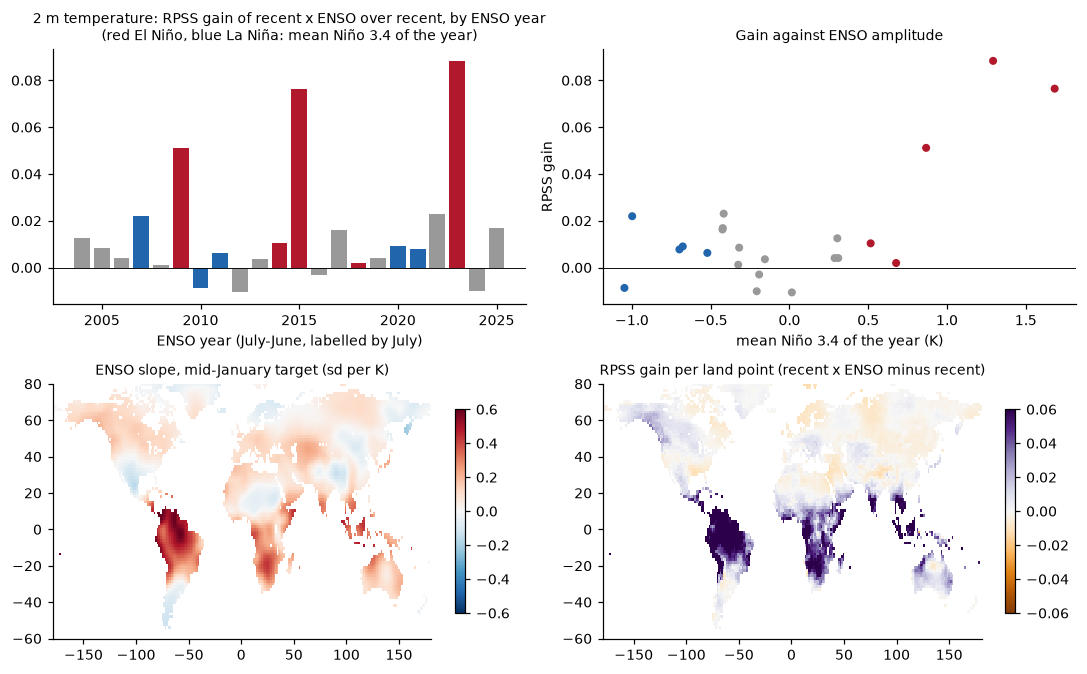

In [10]:
order = np.argsort(lon180)
for v in PILOT_VARS:
    P = PILOT[v]
    fig = plt.figure(figsize=(10, 6.2))
    col = np.where(P["n34y"] >= 0.5, "#b2182b", np.where(P["n34y"] <= -0.5, "#2166ac", "0.6"))
    ax = fig.add_subplot(2, 2, 1)
    ax.bar(P["yrs"], P["dy"], color=col); ax.axhline(0, color="k", lw=0.6)
    ax.set_title(f"{NAMES[v]}: RPSS gain of recent x ENSO over recent, by ENSO year\n(red El Niño, blue La Niña: mean Niño 3.4 of the year)")
    ax.set_xlabel("ENSO year (July-June, labelled by July)")
    ax = fig.add_subplot(2, 2, 2)
    ax.scatter(P["n34y"], P["dy"], c=col, s=18); ax.axhline(0, color="k", lw=0.6)
    ax.set_xlabel("mean Niño 3.4 of the year (K)"); ax.set_ylabel("RPSS gain"); ax.set_title("Gain against ENSO amplitude")
    for j, (ttl, fld, cmap, lim) in enumerate(((f"ENSO slope, mid-January target (sd per K)", P["slope"], "RdBu_r" if v == "tas" else "BrBG", 0.6),
                                               ("RPSS gain per land point (recent x ENSO minus recent)", P["gain_pt"], "PuOr", 0.06))):
        ax = fig.add_subplot(2, 2, 3 + j)
        im = ax.pcolormesh(lon180[order], LAT, r2.scatter(fld, P["points"])[:, order], cmap=cmap, vmin=-lim, vmax=lim, shading="auto")
        ax.set_title(ttl); ax.set_ylim(-60, 80); fig.colorbar(im, ax=ax, shrink=0.8)
    fig.tight_layout(); savefig(fig, f"fig2_enso_pilot_{v}")

## 5. Integration into SeasonBlend (2026 ECMWF forecasts)

The ENSO and IOD slopes are now fitted on **all ERA5 cases whose verifying week ended by
31 December 2025**, so nothing from 2026 enters the prior. They are applied with the Niño 3.4
and DMI values known at each 2026 initialisation. The tilt multiplies SeasonBlend's own prior,
and κ is the median of the values chosen in the nested pilot, not tuned on 2026.

* **Fixed weights:** SeasonBlend's settings and its cross-validated fold weights are kept, and only
  the prior changes. This isolates the prior's contribution.
* **Refitted weights:** the blend weights are re-solved with the new prior, cross-validated in
  the same way.

Scored with the official ERA5 weekly files and quintile boundaries, on the same 2026 weeks.

In [11]:
idx = Indices(cfg)
integ, integ_week, rel26 = [], {}, {}
for var in PILOT_VARS:
    P = PILOT[var]; cases = P["cases"]; has_dmi = np.isfinite(cases.dmi)
    train = np.asarray((cases.start + pd.Timedelta(days=7)) <= pd.Timestamp("2025-12-31"))
    for wv in (1, 2):
        z = rows[(var, wv)]
        inits = [dt.date.fromisoformat(s) for s in z["inits"]]
        st = [idx.state_at(d) for d in inits]
        n34 = np.array([s.nino34 for s in st], float); dmi = np.array([s.iod for s in st], float)
        doys = [day_of_year(dt.date.fromisoformat(m)) for m in z["mondays"]]
        pe, pp, oh = z["p_ens"].astype(float), z["p_prior"].astype(float), z["onehot"].astype(float)
        N = len(pe); W = z["score_weight"]; excl = int(z["exclude_days"])
        fix = cvfix[(var, wv)]
        variants = {"SeasonBlend": pp}
        for name, preds, X in (("ENSO", ["nino34"], n34[:, None]), ("IOD", ["dmi"], dmi[:, None]),
                               ("ENSO+IOD", ["nino34", "dmi"], np.c_[n34, dmi])):
            kap = float(np.median(list(P["chosen"][(name, "recent x")].values())))
            tr = train if name == "ENSO" else train & has_dmi
            mu, s, _ = r2.fit_predict(cases, preds, P["points"], tr, doys, X)
            newp = pp.copy(); flat = newp.reshape(N, 5, -1)
            flat[:, :, P["points"]] = r2.tilt(flat[:, :, P["points"]], r2.gauss_probs(kap * mu, s))
            variants[f"prior x {name}"] = newp
        for vname, pri in variants.items():
            r_fix = np.empty(N)
            keep_p = vname in ("SeasonBlend", "prior x ENSO")
            Pst = np.empty((N, 5) + LA.shape, np.float32) if keep_p else None
            for i in range(N):
                a = fix.a_rows[i][None, :, None]; c = fix.c_rows[i][None, :, None]
                P_ = calib.finalize(a * pe[i] + c * pri[i] + (1 - a - c) * 0.2)
                r_fix[i] = np.nansum(rps_field(P_[None], oh[i][None])[0] * W)
                if keep_p: Pst[i] = P_
            if keep_p:
                rel26[(var, vname, wv)] = (Pst, np.nan_to_num(oh).astype(np.uint8), np.where(np.isfinite(oh[:, 0]), W[None], 0.0))
            T = np.stack([calib.rps_terms(pe[i], pri[i], oh[i], W, np.arange(121), 121) for i in range(N)])
            ref = r1.cv_scores(T[None, None, None], z["mon_ord"], excl, bands)
            integ_week[(var, vname, wv)] = (r_fix, ref.rps, fix.clim)
            integ.append({"variable": var, "variant": vname, "window": wv,
                          "fixed weights RPSS (lb)": float(np.mean(1 - r_fix / fix.clim)),
                          "fixed weights RPSS (ratio)": 1 - r_fix.sum() / fix.clim.sum(),
                          "refitted RPSS (lb)": ref.rpss_leaderboard, "refitted RPSS (ratio)": ref.rpss_ratio})
integ = pd.DataFrame(integ)
integ.to_csv(OUT / "R2_integration_scores.csv", index=False)
print("SeasonBlend rows reproduce SeasonBlend's own cross-validated forecasts (settings fixed at the control fit)")
integ.round(4)

SeasonBlend rows reproduce SeasonBlend's own cross-validated forecasts (settings fixed at the control fit)


,variable,variant,window,fixed weights RPSS (lb),fixed weights RPSS (ratio),refitted RPSS (lb),refitted RPSS (ratio)
0,tas,SeasonBlend,1,0.1079,0.1107,0.1079,0.1107
1,tas,prior x ENSO,1,0.1111,0.1141,0.1111,0.1139
2,tas,prior x IOD,1,0.1078,0.1105,0.1079,0.1107
3,tas,prior x ENSO+IOD,1,0.1111,0.1141,0.1113,0.1141
4,tas,SeasonBlend,2,0.0881,0.0907,0.0881,0.0907
5,tas,prior x ENSO,2,0.0931,0.0959,0.0945,0.0972
6,tas,prior x IOD,2,0.0876,0.0901,0.0877,0.0903
7,tas,prior x ENSO+IOD,2,0.0926,0.0954,0.0938,0.0964


In [12]:
def by_date(arrs):
    # windows 1 and 2 share initialisation dates except the last one (window 2 not yet verified)
    n = max(len(x) for x in arrs)
    return np.vstack([np.r_[x, np.full(n - len(x), np.nan)] for x in arrs])

boot = []
for vname in ("prior x ENSO", "prior x IOD", "prior x ENSO+IOD"):
    for mode, j in (("fixed weights", 0), ("refitted weights", 1)):
        for var in PILOT_VARS + (["tas+pr"] if len(PILOT_VARS) > 1 else []):
            vs = PILOT_VARS if var == "tas+pr" else [var]
            A_ = by_date([integ_week[(x, "SeasonBlend", wv)][j] for x in vs for wv in (1, 2)])
            B_ = by_date([integ_week[(x, vname, wv)][j] for x in vs for wv in (1, 2)])
            Cl = by_date([integ_week[(x, "SeasonBlend", wv)][2] for x in vs for wv in (1, 2)])
            d = r1.block_bootstrap_delta(A_, B_, Cl, block=4, n_boot=4000, convention="leaderboard")
            boot.append({"variant": vname, "mode": mode, "variables": var, "delta (mean of pairs)": d["est"],
                         "lo90": d["lo90"], "hi90": d["hi90"], "P(better)": d["p_better"],
                         "headline delta (pairs / 6)": d["est"] * A_.shape[0] / 6})
boot = pd.DataFrame(boot)
boot.to_csv(OUT / "R2_integration_bootstrap.csv", index=False)
print("Variant minus SeasonBlend (leaderboard convention), both windows; 4-week moving blocks, 4000 samples.\n"
      "'headline delta' converts to the 6-pair mean RPSS that ranks teams.")
boot.round(4)

Variant minus SeasonBlend (leaderboard convention), both windows; 4-week moving blocks, 4000 samples.
'headline delta' converts to the 6-pair mean RPSS that ranks teams.


,variant,mode,variables,delta (mean of pairs),lo90,hi90,P(better),headline delta (pairs / 6)
0,prior x ENSO,fixed weights,tas,0.0041,0.0003,0.0080,0.9592,0.0014
1,prior x ENSO,refitted weights,tas,0.0048,0.0024,0.0071,0.9995,0.0016
2,prior x IOD,fixed weights,tas,-0.0003,-0.0010,0.0002,0.1972,-0.0001
3,prior x IOD,refitted weights,tas,-0.0002,-0.0009,0.0004,0.3782,-0.0001
4,prior x ENSO+IOD,fixed weights,tas,0.0039,0.0006,0.0071,0.9760,0.0013
5,prior x ENSO+IOD,refitted weights,tas,0.0045,0.0017,0.0073,0.9948,0.0015


2026 reliability component x 1000 (fixed weights, official ERA5 categories; lower is better)


,variable,window,model,q1,q2,q3,q4,q5,mean
0,tas,1,SeasonBlend,1.359,0.021,0.248,0.376,0.794,0.560
1,tas,1,prior x ENSO,1.182,0.053,0.295,0.377,1.191,0.620
2,tas,2,SeasonBlend,1.455,0.009,0.230,0.343,0.804,0.568
3,tas,2,prior x ENSO,1.285,0.034,0.278,0.331,1.285,0.643


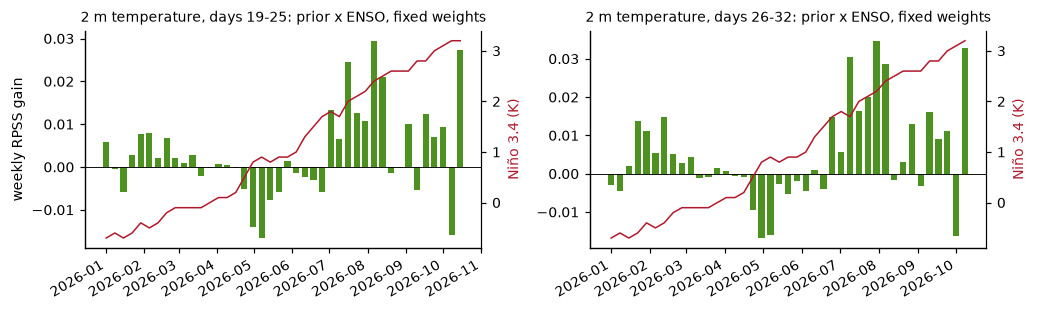

In [13]:
r26 = []
for (var, vname, wv), (Pst, ohs, Ws) in rel26.items():
    rc = r2.reliability_component(Pst, ohs, Ws)
    r26.append({"variable": var, "window": wv, "model": vname, **{f"q{k + 1}": rc[k] * 1000 for k in range(5)}, "mean": rc.mean() * 1000})
r26 = pd.DataFrame(r26)
r26.to_csv(OUT / "R2_integration_reliability.csv", index=False)
print("2026 reliability component x 1000 (fixed weights, official ERA5 categories; lower is better)")
display(r26.round(3))
del rel26

fig, axs = plt.subplots(len(PILOT_VARS), 2, figsize=(9.5, 2.9 * len(PILOT_VARS)), sharey=False, squeeze=False)
for r_, var in enumerate(PILOT_VARS):
    for c_, wv in enumerate((1, 2)):
        ax = axs[r_, c_]; z = rows[(var, wv)]; d0 = pd.to_datetime(z["inits"])
        a_, _, cl = integ_week[(var, "SeasonBlend", wv)]; b_ = integ_week[(var, "prior x ENSO", wv)][0]
        ax.bar(d0, (a_ - b_) / cl, width=5, color="#4d9221"); ax.axhline(0, color="k", lw=0.6)
        ax.set_title(f"{NAMES[var]}, {WIN[wv]}: prior x ENSO, fixed weights")
        ax2 = ax.twinx(); ax2.plot(d0, [idx.state_at(d.date()).nino34 for d in d0], color="#b2182b", lw=1)
        ax2.set_ylabel("Niño 3.4 (K)", color="#b2182b"); ax2.spines["right"].set_visible(True)
        if c_ == 0: ax.set_ylabel("weekly RPSS gain")
fig.autofmt_xdate(); fig.tight_layout(); savefig(fig, "fig3_integration_weekly")

## 6. Lagged ensemble pilot

ECMWF runs its extended-range ensemble every day. The rules allow any data timestamped at or
before Thursday 00 UTC, so the Wednesday (lag 1) and Monday (lag 3) runs of the same week can
join the Thursday run. They target the same calendar weeks at leads 1 or 3 days longer. Each lag
gets its own leave-one-out bias correction, with SeasonBlend's λ, spread and smoothing. The
members are pooled, weighted equally per run, and the blend weights are re-solved and
cross-validated exactly as for SeasonBlend. Comparison: Thursday-only SeasonBlend with the
same fixed settings, on the same weeks.

In [14]:
# free the pilot's large arrays before loading ensemble members
for v in PILOT:   # keep the pilot tables, drop the large per-case arrays before loading ensemble members
    PILOT[v].pop("cases", None)
import gc; gc.collect()
LAG_RESULTS = OUT / "R2_lagged_scores.csv"
from aiwq import research_lag
from aiwq.ens import load_members
from aiwq.fit import training_data, prior_for, prior_data, PRIOR_GAP_DAYS
lag_ready = {lag: sum(research_lag.lag_path(cfg, dt.date.fromisoformat(d), lag, v).exists()
                      for d in rows[("tas", 1)]["inits"] for v in VARIABLES) for lag in (1, 3)}
print("lagged files present (of", 3 * len(rows[("tas", 1)]["inits"]), "per lag):", lag_ready)

lagged files present (of 126 per lag): {1: 123, 3: 123}


In [15]:
VARIANTS = ((), (1,), (1, 3))

def lagged_terms(v, w):
    # per-week band-row terms for Thursday only, Thursday + Wednesday, Thursday + Wednesday + Monday,
    # with SeasonBlend's settings; all on the weeks where both lagged runs exist
    z = rows[(v, w)]; p = control[v][str(w)]
    lam, s, sp = p["lam"], p["s"], p["sigma_p"]
    tr = training_data(cfg, v, w, download=False)
    inits = list(tr.inits)
    assert [d.isoformat() for d in inits] == list(z["inits"])
    ok = np.array([all(research_lag.lag_path(cfg, d, l, v).exists() for l in (1, 3)) for d in inits])
    runs = {0: [load_members(cfg, d, v, w) for d in inits]}
    for lag in (1, 3):
        runs[lag] = [research_lag.load_lagged(cfg, d, lag, v, w) if ok[i] else None for i, d in enumerate(inits)]
    N = len(inits); doys = tr.doys; mon_ord = np.array([m.toordinal() for m in tr.mondays])
    W = z["score_weight"]; pp = z["p_prior"].astype(float); oh = z["onehot"].astype(float)
    means = {l: np.stack([np.nanmean(X, 0) if X is not None else np.full(LA.shape, np.nan) for X in runs[l]]) for l in runs}
    T = {var_: np.full((N, 121, 6), np.nan) for var_ in VARIANTS}
    for i in range(N):
        if not ok[i]:
            continue
        keep = (np.abs(mon_ord - mon_ord[i]) >= cfg.exclude_days) & ok
        w_i = calib.season_weights(doys[i], doys, cfg.season_sigma_days, cfg.season_floor) * keep
        probs_l = {}
        for l in runs:
            corr = calib.correction_field(v, means[l], tr.obs, w_i, cfg.bias_smooth_sigma)
            Xl = calib.apply_correction(v, runs[l][i], corr, lam)
            probs_l[l] = calib.categorize(calib.scale_spread(v, Xl, s, mean=np.nanmean(Xl, 0)), tr.bounds[i])
        for var_ in VARIANTS:
            pe = calib.smooth_probs(np.mean([probs_l[l] for l in (0,) + var_], axis=0), sp)
            T[var_][i] = calib.rps_terms(pe, pp[i], oh[i], W, np.arange(121), 121)
    del runs
    return T, ok, mon_ord

lag_rows, lag_week = [], {}
if min(lag_ready.values()) >= 3 * (len(rows[("tas", 1)]["inits"]) - 1):
    t0 = time.time()
    for v, w in PAIRS:
        z = rows[(v, w)]; excl = int(z["exclude_days"])
        T, ok, mo = lagged_terms(v, w)
        for lags in VARIANTS:
            res = r1.cv_scores(T[lags][ok][None, None, None], mo[ok], excl, bands)
            lag_week[(v, w, lags)] = (res.rps, res.clim, np.flatnonzero(ok))
            lag_rows.append({"variable": v, "window": w, "runs": "Thu" + "".join(f"+lag{l}" for l in lags),
                             "weeks": int(ok.sum()), "RPSS (lb)": res.rpss_leaderboard, "RPSS (ratio)": res.rpss_ratio})
        print(f"  {v} p{w}: {time.time() - t0:.0f} s")
    lagtab = pd.DataFrame(lag_rows)
    lagtab.to_csv(LAG_RESULTS, index=False)
    display(lagtab.pivot_table(index=["variable", "window"], columns="runs", values="RPSS (lb)").round(4))
else:
    print("Lagged runs not all downloaded yet; run `python -m aiwq.research_lag` and re-run this section.")

  tas p1: 81 s


  tas p2: 160 s


  mslp p1: 244 s


  mslp p2: 323 s


  pr p1: 393 s


  pr p2: 442 s


runs                Thu  Thu+lag1  Thu+lag1+lag3
variable window                                 
mslp     1       0.1921    0.1878         0.1832
         2       0.1535    0.1532         0.1516
pr       1       0.0825    0.0827         0.0821
         2       0.0713    0.0719         0.0716
tas      1       0.1120    0.1110         0.1090
         2       0.0924    0.0920         0.0914

In [16]:
lag_boot = []
if lag_week:
    for lags in ((1,), (1, 3)):
        A_, B_, Cl = [], [], []
        common = None
        for v, w in PAIRS:
            ia = lag_week[(v, w, ())][2]; ib = lag_week[(v, w, lags)][2]
            assert np.array_equal(ia, ib)
        n = max(len(lag_week[(v, w, ())][0]) for v, w in PAIRS)
        def pad(x): return np.r_[x, np.full(n - len(x), np.nan)]
        A_ = np.vstack([pad(lag_week[(v, w, ())][0]) for v, w in PAIRS])
        B_ = np.vstack([pad(lag_week[(v, w, lags)][0]) for v, w in PAIRS])
        Cl = np.vstack([pad(lag_week[(v, w, ())][1]) for v, w in PAIRS])
        for conv in ("leaderboard", "ratio"):
            for block in (1, 4):
                d = r1.block_bootstrap_delta(A_, B_, Cl, block=block, n_boot=4000, convention=conv)
                lag_boot.append({"runs": "Thu" + "".join(f"+lag{l}" for l in lags), "convention": conv, "block": block,
                                 "headline delta": d["est"], "lo90": d["lo90"], "hi90": d["hi90"], "P(better)": d["p_better"]})
        for j, (v, w) in enumerate(PAIRS):
            d = r1.block_bootstrap_delta(A_[j], B_[j], Cl[j], block=4, n_boot=4000)
            lag_boot.append({"runs": "Thu" + "".join(f"+lag{l}" for l in lags), "convention": f"leaderboard {v} p{w}",
                             "block": 4, "headline delta": d["est"], "lo90": d["lo90"], "hi90": d["hi90"], "P(better)": d["p_better"]})
    lag_boot = pd.DataFrame(lag_boot)
    lag_boot.to_csv(OUT / "R2_lagged_bootstrap.csv", index=False)
    display(lag_boot.round(4))

,runs,convention,block,headline delta,lo90,hi90,P(better)
0,Thu+lag1,leaderboard,1,-0.0009,-0.0020,0.0004,0.1220
1,Thu+lag1,leaderboard,4,-0.0009,-0.0019,0.0002,0.0860
2,Thu+lag1,ratio,1,-0.0009,-0.0020,0.0004,0.1268
3,Thu+lag1,ratio,4,-0.0009,-0.0019,0.0002,0.0902
4,Thu+lag1,leaderboard tas p1,4,-0.0010,-0.0028,0.0006,0.1770
5,Thu+lag1,leaderboard tas p2,4,-0.0004,-0.0014,0.0007,0.2728
6,Thu+lag1,leaderboard mslp p1,4,-0.0042,-0.0083,0.0001,0.0532
7,Thu+lag1,leaderboard mslp p2,4,-0.0003,-0.0028,0.0017,0.4325
8,Thu+lag1,leaderboard pr p1,4,0.0001,-0.0007,0.0009,0.5980
9,Thu+lag1,leaderboard pr p2,4,0.0006,-0.0000,0.0012,0.9498


## 7. Ranking and decision

Headline points are the change in the mean RPSS over the six variable/window pairs, the score
that ranks teams. SeasonBlend's cross-validated headline is +0.112.

| Rank | Candidate | Measured or bounded gain (headline) | Evidence | Cost | Risk |
|---|---|---|---|---|---|
| 1 | **ENSO-tilted prior** (tas now, pr next) | tas: **+0.0016** (refitted; 90 % +0.0008 to +0.0024 when scaled from +0.0048 for tas). pr not yet measured | ERA5 21 years, 18/22 years better; 2026 SeasonBlend test positive with fixed and refitted weights | Low: one weekly index value, one-off ERA5 history | Low: the blend weight caps the damage; no ENSO effect in the extratropics, so nothing is lost there |
| 2 | Recalibration of SeasonBlend's own probabilities | at most 0.0032 (in-sample upper bound), realistic ≤ 0.001 | Reliability decomposition on 2026 | Low | Overfitting: R1 showed extra parameters lose out of sample |
| 3 | More training weeks (reforecasts) for weight fitting | ≈ 0.0005-0.001 (learning curve flat from 10 to 36 weeks) | Learning curve; does not measure the bias correction's own sample size | High: licence, large download | Low |
| 4 | Independent second forecast system (multi-model) for the northern extratropics | unknown | The northern extratropics hold 36 % of the climatological RPS at RPSS 0.045, and ENSO does not help there | High: data access and timing checks | Medium |
| - | Lagged ECMWF runs (Wed, Mon) | **−0.0009** (Wed), **−0.0025** (Wed + Mon) | 2026, 40-41 weeks, all six pairs | - | Dropped |
| - | IOD conditioning | ≈ 0 (tas −0.0001) | ERA5 18 years and 2026 | - | Dropped |
| - | Equatorial East Africa or southern-band fixes | ≤ 0.0004 and ≈ 0.001 | Region decomposition | - | Not worth a model change |

**Decision.** SeasonBlend stays unchanged and is safe to run on Saturday. The ENSO-tilted prior is
the only candidate with credible, repeatable evidence. It stays experimental until the
precipitation pilot is done. It is then a candidate **second model** ("SeasonBlend-ENSO"). It
cannot be period-ranked in DJF 2026 (it missed weeks 1-2), so it should run as a shadow forecast
each week now, and enter as a ranked model from MAM 2027 (11 February 2027) if its live weekly
scores agree with this backtest.

In [17]:
decision = {
    "date": dt.date.today().isoformat(), "branch": branch, "commit": commit,
    "operational_model": "SeasonBlend unchanged (data/params.json not modified)",
    "weakness_points_mean": weak.iloc[-1].drop(["variable", "window", "N"]).to_dict(),
    "learning_curve_fit": {"A": float(lc_A), "b": float(lc_b), **{k: float(x) for k, x in extrap.items()}},
    "pilot_nested": honest_tab.to_dict(orient="records"),
    "integration_bootstrap": boot.to_dict(orient="records"),
    "lagged_bootstrap": (lag_boot.to_dict(orient="records") if len(lag_boot) else "not run"),
    "promote_to_seasonblend": False,
}
(OUT / "R2_decision.json").write_text(json.dumps(decision, indent=1, default=float))
prov = {"generated_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"), "git_commit": commit, "branch": branch,
        "era5_daily": {v: f"data/cds/{v}_daily_2004..2026.nc (CDS, 1.5 deg daily means)" for v in PILOT},
        "pilot": {v: {"points": PILOT[v]["audit"][0], "daily_from": PILOT[v]["audit"][1], "daily_to": PILOT[v]["audit"][2],
                      "cases": PILOT[v]["audit"][3], "cases_with_dmi": PILOT[v]["audit"][4], "kappa_used": PILOT[v]["kap_star"]}
                  for v in PILOT}, "pilot_folds": int(len(audit)),
        "indices": {"nino34": "NOAA CPC wksst9120.for, lag 8 d", "dmi": "BoM iod_1.txt weekly, lag 4 d (from 2008-08)"},
        "ens": "ECMWF IFS ENS via dynamical.org; Thursday runs data/ens, lagged runs data/research/ens_lag",
        "software": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                     "scipy": scipy.__version__, "matplotlib": matplotlib.__version__},
        "runtime_s": round(time.time() - t_start)}
(OUT / "provenance.json").write_text(json.dumps(prov, indent=1))
print(json.dumps(prov, indent=1))

{
 "generated_utc": "2026-11-19T05:57:21+00:00",
 "git_commit": "1299384",
 "branch": "research/r2",
 "era5_daily": {
  "tas": "data/cds/tas_daily_2004..2026.nc (CDS, 1.5 deg daily means)"
 },
 "pilot": {
  "tas": {
   "points": 9839,
   "daily_from": "2004-01-01",
   "daily_to": "2026-11-09",
   "cases": 2190,
   "cases_with_dmi": 1816,
   "kappa_used": 1.0
  }
 },
 "pilot_folds": 22,
 "indices": {
  "nino34": "NOAA CPC wksst9120.for, lag 8 d",
  "dmi": "BoM iod_1.txt weekly, lag 4 d (from 2008-08)"
 },
 "ens": "ECMWF IFS ENS via dynamical.org; Thursday runs data/ens, lagged runs data/research/ens_lag",
 "software": {
  "python": "3.14.2",
  "numpy": "2.5.4",
  "pandas": "3.1.1",
  "scipy": "1.17.1",
  "matplotlib": "3.11.2"
 },
 "runtime_s": 1462
}


## Conclusions

1. **Where the points are.** SeasonBlend loses most of its headline score in the northern
   extratropics: RPSS 0.045 on 36 % of the climatological RPS. Fixable weaknesses in R1 are small.
   - Weight noise: 0.004 in-sample, but the learning curve is flat, so it is optimism rather than
     data shortage.
   - Calibration headroom: ≤ 0.003.
   - Coldest-quintile over-forecast: 0.0009.
   - South of 30°S against the raw ensemble: ≈ 0.001.
   - Equatorial East Africa: ≤ 0.0004 headline points.

   Days 26-32 score 0.024 below days 19-25 (0.100 against 0.123), in every variable; that is predictability, not a fixable bias.
2. **ENSO works, IOD does not.** On 21 independent ERA5 years (2 m temperature, land), tilting
   SeasonBlend's prior by Niño 3.4 adds +0.015 RPSS (90 % +0.007 to +0.024; 18 of 22 years
   better). κ = 1 is chosen without peeking. The gain comes from the tropics (+0.034) and Africa
   (+0.021; East Africa +0.030, Southern Africa +0.039), and rises to +0.048 when |Niño 3.4| ≥ 1 K.
   It lowers the prior's reliability component from 1.43 to 1.19 ×10⁻³. The gain is asymmetric:
   El Niño years carry it (2009, 2015 and 2023 gain +0.05 to +0.09), and La Niña years gain little.
   The IOD adds nothing, alone or with ENSO.
3. **It transfers to SeasonBlend.** With slopes fitted on ERA5 up to 2025 and SeasonBlend's
   cross-validated weights unchanged, 2026 temperature RPSS rises by +0.0041 (90 % +0.0003 to
   +0.0080). With refitted weights it rises by +0.0048 (+0.0024 to +0.0071). That is **+0.0016 on
   the headline score**. The weekly gains appear after July, once Niño 3.4 passed about 1.5 K, which
   is the state of the coming DJF weeks (+3 K). Calibration is mixed: the coldest-quintile
   over-forecast eases (reliability 1.36 → 1.18 ×10⁻³), but the warmest quintile becomes
   over-forecast (0.79 → 1.19). The mean reliability component rises from 0.56 to 0.62, so the
   RPSS gain comes from resolution. 2026 is one strongly trending ENSO year, so this is a
   confirmation, not a proof. A damped κ for the warm tail is worth a check before any live use.
4. **The lagged ensemble hurts.** Pooling the Wednesday run costs −0.0009 and adding Monday too
   costs −0.0025 (−0.0040 to −0.0010), mostly through pressure at days 19-25. The older runs
   dilute the newest one more than their extra members help.
5. **Limits.** The pilot uses all-other-years quintile boundaries, not the official trailing 20
   years (ERA5 here starts in 2004). It covers 2 m temperature only, because precipitation
   2004-2026 is still downloading (6 of 23 years). Pressure is excluded because SeasonBlend gives
   its prior almost no weight. The learning curve does not measure the bias correction's own
   sample size.

**Next experiment:** the same pilot for precipitation (it runs automatically here once the ERA5
years are complete). Precipitation is where SeasonBlend leans most on its prior in the tropics
(c ≈ 0.37-0.41). Then SeasonBlend-ENSO runs as a weekly shadow forecast, compared with
SeasonBlend on the official verification.